# VideoSense: end-to-end Colab driver (A100)

Run the cells top to bottom. Each section matches a part of the handout.

**Before you start**
1. Upload the `videosense/` folder to Google Drive at `MyDrive/videosense`.
2. Choose *Runtime → Change runtime type → A100 GPU* (High-RAM if offered).

The code runs from local disk (`/content/videosense`), which is much faster
than Drive. After each part, `sync()` copies `models/`, `results/` and
`figures/` back to Drive. The UCF101 archive and the preprocessing caches are
also stored on Drive, so a new session can skip the download and
preprocessing.

Approximate A100 timings: download 15–60 min (depends on the CRCV server),
extraction ~3 min, frame cache + flow ~15 min, Part 2 ~25 min,
Part 3 ~40 min, Part 4 ~35 min, Part 5 ~10 min.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import os, torch
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(),
      '| bf16', torch.cuda.is_available() and torch.cuda.is_bf16_supported())

name, memory.total [MiB]
NVIDIA A100-SXM4-80GB, 81920 MiB
torch 2.11.0+cu130 | CUDA True | bf16 True


## 0. Setup: Drive, code, packages

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_PROJECT = '/content/drive/MyDrive/videosense'      # code + outputs
DRIVE_DATA = '/content/drive/MyDrive/videosense_data'    # rar + caches
WORK = '/content/videosense'
os.makedirs(DRIVE_DATA, exist_ok=True)
!rsync -a --exclude data "{DRIVE_PROJECT}/" "{WORK}/"
%cd {WORK}
!pip install -q torchinfo
!apt-get -qq install -y unrar > /dev/null
!python setup_project.py

def sync():
    """Copy outputs back to Drive (run after every part)."""
    !rsync -a --exclude '*_best.pt' models results figures "{DRIVE_PROJECT}/"
    print('synced to', DRIVE_PROJECT)

Mounted at /content/drive
/content/videosense
ok  data/UCF101/
ok  data/optical_flow/
ok  data/splits/
ok  data/frame_cache/
ok  models/
ok  utils/
ok  results/
ok  figures/
ok  figures/gradcam/


## 1. Data: UCF101 download, extraction, mini subset

The `.rar` file is kept on Drive so it only has to be downloaded once.

In [3]:
RAR = f'{DRIVE_DATA}/UCF101.rar'
SPLITS = f'{DRIVE_DATA}/UCF101TrainTestSplits-RecognitionTask.zip'
if not os.path.exists(RAR):
    !wget -q --show-progress --no-check-certificate -O "{RAR}" https://www.crcv.ucf.edu/data/UCF101/UCF101.rar
if not os.path.exists(SPLITS):
    !wget -q --no-check-certificate -O "{SPLITS}" https://www.crcv.ucf.edu/data/UCF101/UCF101TrainTestSplits-RecognitionTask.zip
!ls -lh "{DRIVE_DATA}"

/content/drive/MyDr  15%[==>                 ]   1.01G  12.8MB/s    in 82s     
/content/drive/MyDr  31%[+++==>              ]   2.02G  12.2MB/s    in 86s     
/content/drive/MyDr  46%[++++++==>           ]   3.03G  13.2MB/s    in 82s     
/content/drive/MyDr  62%[+++++++++==>        ]   4.04G  13.1MB/s    in 79s     
/content/drive/MyDr  78%[++++++++++++==>     ]   5.05G  13.4MB/s    in 82s     
/content/drive/MyDr  93%[+++++++++++++++==>  ]   6.06G  11.9MB/s    in 86s     
/content/drive/MyDr 100%[++++++++++++++++++=>]   6.46G  5.59MB/s    in 64s     
total 6.5G
-rw------- 1 root root 6.5G Nov 21  2012 UCF101.rar
-rw------- 1 root root 112K Oct 18  2013 UCF101TrainTestSplits-RecognitionTask.zip


In [4]:
if not os.path.isdir('data/UCF101/Basketball'):
    !unrar x -idq "{RAR}" data/
    !rm -rf data/UCF101 && mv data/UCF-101 data/UCF101
!unzip -qo "{SPLITS}" -d data/splits/
!python subset_classes.py
!python prepare_data.py --verify

Mini dataset ready: 10 classes, 1212 videos
data/UCF101: 101 classes, 13320 videos (full UCF101 = 101 classes, 13,320 videos)
  trainlist01.txt: 9537 entries
  testlist01.txt: 3783 entries
data/UCF101_mini: 10 classes, 1212 videos (full UCF101 = 101 classes, 13,320 videos)
  trainlist01.txt: 870 entries
  testlist01.txt: 342 entries


### Preprocessing (frame cache + optical flow)

This is a one-time step. If a previous session saved the caches to Drive,
they are restored here instead of being recomputed.

In [5]:
CACHE_TAR = f'{DRIVE_DATA}/caches.tar'
if os.path.exists(CACHE_TAR):
    !tar -xf "{CACHE_TAR}" -C data/
    !mkdir -p results && cp "{DRIVE_DATA}/base_classes.txt" results/ 2>/dev/null || true
!python prepare_data.py --frames mini base --flow --workers {os.cpu_count()}
if not os.path.exists(CACHE_TAR):
    !tar -cf "{CACHE_TAR}" -C data frame_cache optical_flow
    !cp results/base_classes.txt "{DRIVE_DATA}/"
!du -sh data/frame_cache data/optical_flow

Caching frames: 100% 1212/1212 [00:16<00:00, 75.49it/s] 
Frame cache ready: 1212 videos -> data/frame_cache
Caching frames: 100% 4077/4077 [00:59<00:00, 68.04it/s]
Frame cache ready: 4077 videos -> data/frame_cache
Computing optical flow: 100% 1212/1212 [00:31<00:00, 37.88it/s]
Optical flow preprocessing complete! (1212 videos)
11G	data/frame_cache
1.9G	data/optical_flow


## Part 1: Video preprocessing and optical flow

saved figures/part1_sampled_frames.png
saved figures/part1_flow_components.png
saved figures/part1_flow_comparison.png
saved figures/part1_camera_motion.png
RGB clip tensor: shape (3, 16, 112, 112) (C, T, H, W), dtype torch.float32, mean 1.201, std 0.954, label 0 (Archery)
Flow stack: shape (2, 16, 112, 112) (2, T, H, W), dtype float32, |flow| max 13.34 px



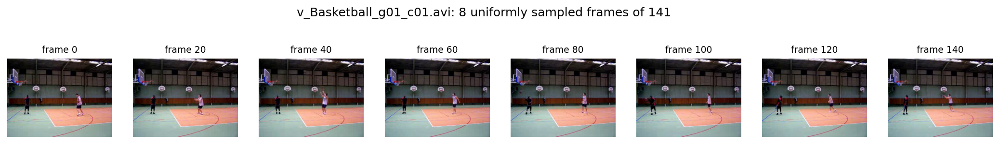

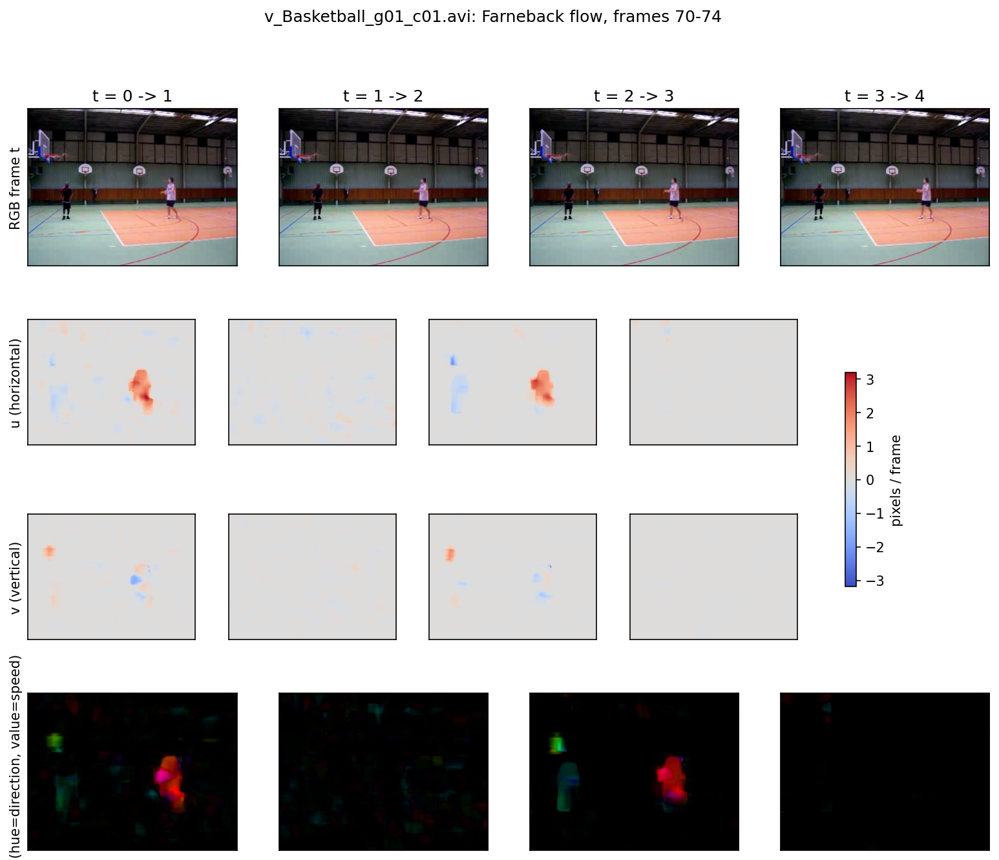

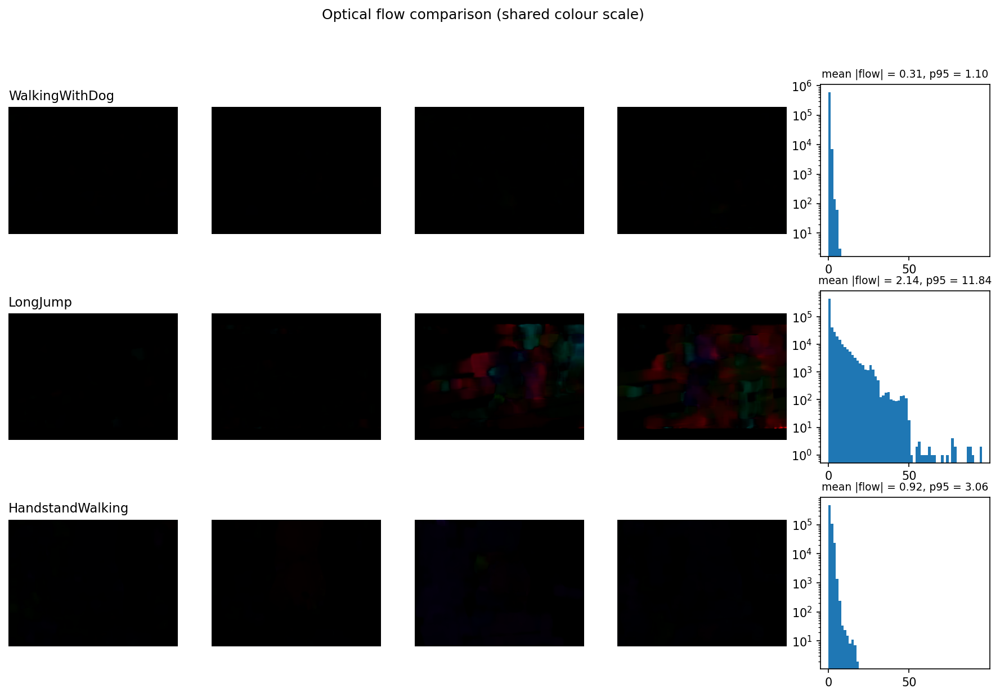

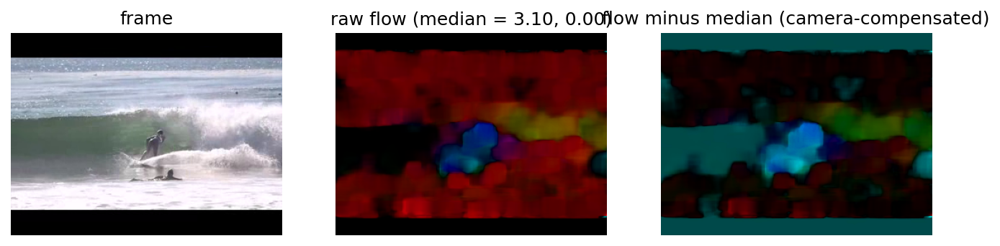

RGB clip tensor: shape (3, 16, 112, 112) (C, T, H, W), dtype torch.float32, mean 1.201, std 0.954, label 0 (Archery)
Flow stack: shape (2, 16, 112, 112) (2, T, H, W), dtype float32, |flow| max 13.34 px

synced to /content/drive/MyDrive/videosense


In [6]:
!python part1_visualize.py
from IPython.display import Image, display
for f in ['part1_sampled_frames', 'part1_flow_components',
          'part1_flow_comparison', 'part1_camera_motion']:
    display(Image(f'figures/{f}.png', width=1100))
print(open('figures/part1_tensor_check.txt').read())
sync()

## Part 2: 3D CNN (C3D from scratch, R(2+1)D fine-tuning)

* Ex. 6–7: C3D, 30 epochs, label smoothing 0.1 → `models/c3d_ucf101.pt`
* Ex. 8: label-smoothing sweep over {0.0, 0.1, 0.2}
* Ex. 9: R(2+1)D-18 pretrained on Kinetics-400, only the head is fine-tuned, 10 epochs
* Ex. 10: torchinfo parameter and FLOP counts (also printed by each run)

In [7]:
!python -m models.cnn3d
!python train_3dcnn.py --model c3d --label_smoothing 0.1 --epochs 30

input          (1, 3, 16, 112, 112)
after MaxPool3d (1, 64, 16, 56, 56)
after MaxPool3d (1, 128, 8, 28, 28)
after MaxPool3d (1, 256, 4, 14, 14)
after MaxPool3d (1, 512, 2, 7, 7)
after MaxPool3d (1, 512, 1, 3, 3)
logits         (1, 10)
R2Plus1DBlock   (1, 128, 4, 14, 14)
Training on: cuda
10 classes | train 870 | val 342 clips
params 63,362,186 (trainable 63,362,186) | 77.1 GFLOPs / clip
Epoch 1/30 | Loss: 2.6076 | Train Acc: 0.131 | Val Loss: 2.3560 | Val Top-1: 0.135 | Val Top-5: 0.558
Epoch 2/30 | Loss: 2.2536 | Train Acc: 0.177 | Val Loss: 2.3851 | Val Top-1: 0.158 | Val Top-5: 0.576
Epoch 3/30 | Loss: 2.1380 | Train Acc: 0.252 | Val Loss: 2.1568 | Val Top-1: 0.202 | Val Top-5: 0.678
Epoch 4/30 | Loss: 2.0577 | Train Acc: 0.286 | Val Loss: 2.3345 | Val Top-1: 0.161 | Val Top-5: 0.643
Epoch 5/30 | Loss: 2.0568 | Train Acc: 0.285 | Val Loss: 2.3575 | Val Top-1: 0.178 | Val Top-5: 0.643
Epoch 6/30 | Loss: 1.9349 | Train Acc: 0.333 | Val Loss: 2.2773 | Val Top-1: 0.205 | Val Top-5: 0.64

In [8]:
!python train_3dcnn.py --model c3d --label_smoothing 0.0 --run_name c3d_ls0.0
!python train_3dcnn.py --model c3d --label_smoothing 0.2 --run_name c3d_ls0.2

Training on: cuda
10 classes | train 870 | val 342 clips
params 63,362,186 (trainable 63,362,186) | 77.1 GFLOPs / clip
Epoch 1/30 | Loss: 2.6139 | Train Acc: 0.138 | Val Loss: 2.4094 | Val Top-1: 0.132 | Val Top-5: 0.518
Epoch 2/30 | Loss: 2.2245 | Train Acc: 0.174 | Val Loss: 2.5479 | Val Top-1: 0.143 | Val Top-5: 0.640
Epoch 3/30 | Loss: 2.1174 | Train Acc: 0.221 | Val Loss: 2.1093 | Val Top-1: 0.225 | Val Top-5: 0.667
Epoch 4/30 | Loss: 1.9992 | Train Acc: 0.274 | Val Loss: 2.4859 | Val Top-1: 0.213 | Val Top-5: 0.611
Epoch 5/30 | Loss: 1.9473 | Train Acc: 0.293 | Val Loss: 2.4273 | Val Top-1: 0.178 | Val Top-5: 0.573
Epoch 6/30 | Loss: 1.8138 | Train Acc: 0.326 | Val Loss: 2.2036 | Val Top-1: 0.196 | Val Top-5: 0.675
Epoch 7/30 | Loss: 1.7633 | Train Acc: 0.358 | Val Loss: 2.1716 | Val Top-1: 0.281 | Val Top-5: 0.699
Epoch 8/30 | Loss: 1.6821 | Train Acc: 0.372 | Val Loss: 1.9045 | Val Top-1: 0.313 | Val Top-5: 0.763
Epoch 9/30 | Loss: 1.5862 | Train Acc: 0.429 | Val Loss: 2.0848 |

Training on: cuda
10 classes | train 870 | val 342 clips
Downloading: "https://download.pytorch.org/models/r2plus1d_18-91a641e6.pth" to /root/.cache/torch/hub/checkpoints/r2plus1d_18-91a641e6.pth
100% 120M/120M [00:01<00:00, 88.3MB/s]
params 31,305,255 (trainable 5,130) | 81.0 GFLOPs / clip
Epoch 1/10 | Loss: 1.5139 | Train Acc: 0.703 | Val Loss: 1.0420 | Val Top-1: 0.860 | Val Top-5: 0.985
Epoch 2/10 | Loss: 0.7809 | Train Acc: 0.972 | Val Loss: 0.7996 | Val Top-1: 0.921 | Val Top-5: 1.000
Epoch 3/10 | Loss: 0.6569 | Train Acc: 0.992 | Val Loss: 0.7419 | Val Top-1: 0.939 | Val Top-5: 1.000
Epoch 4/10 | Loss: 0.6197 | Train Acc: 0.995 | Val Loss: 0.7355 | Val Top-1: 0.921 | Val Top-5: 1.000
Epoch 5/10 | Loss: 0.6059 | Train Acc: 0.994 | Val Loss: 0.7167 | Val Top-1: 0.939 | Val Top-5: 1.000
Epoch 6/10 | Loss: 0.5890 | Train Acc: 0.998 | Val Loss: 0.7122 | Val Top-1: 0.939 | Val Top-5: 1.000
Epoch 7/10 | Loss: 0.5883 | Train Acc: 0.999 | Val Loss: 0.7168 | Val Top-1: 0.939 | Val Top-5: 

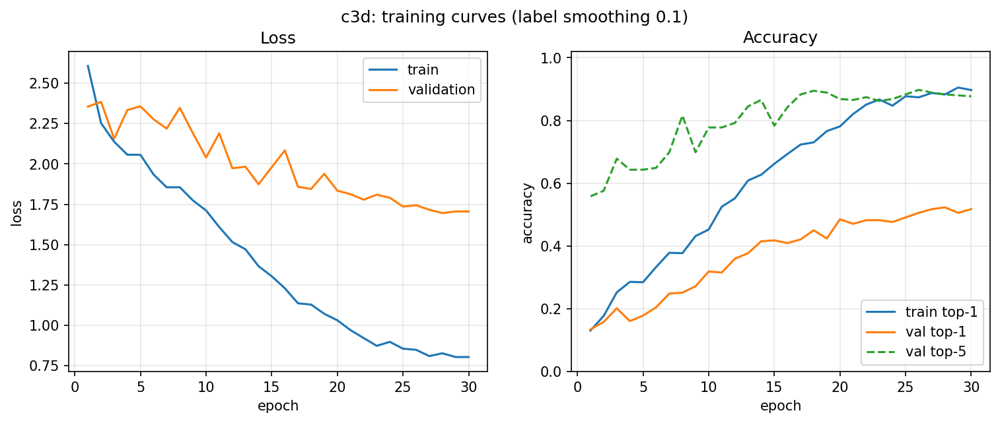

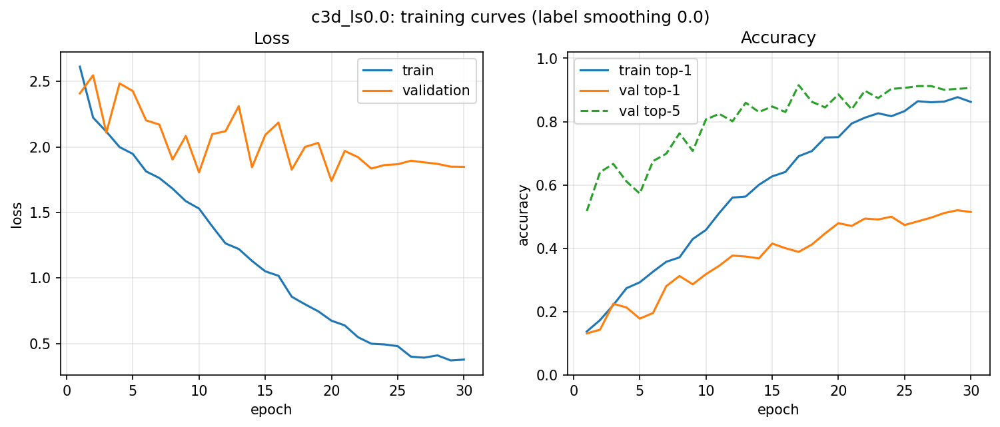

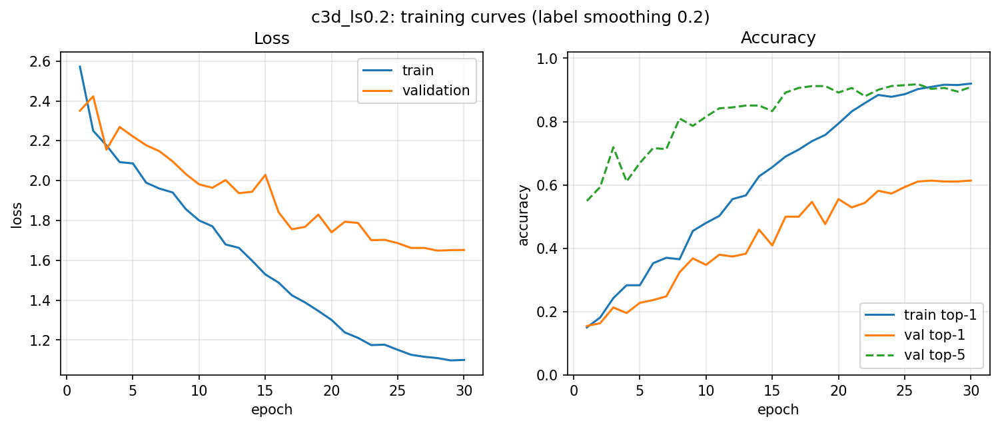

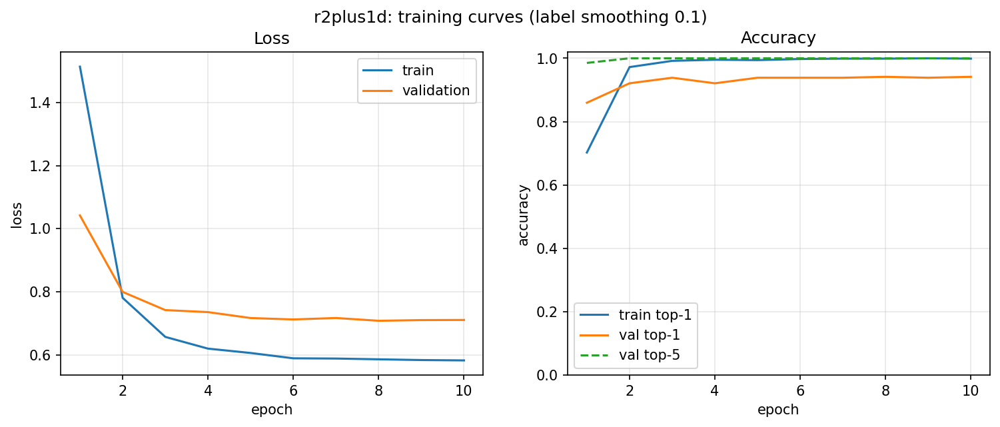

synced to /content/drive/MyDrive/videosense


In [9]:
!python train_3dcnn.py --model r2plus1d --epochs 10 --lr 1e-3
for f in ['c3d', 'c3d_ls0.0', 'c3d_ls0.2', 'r2plus1d']:
    display(Image(f'figures/{f}_curves.png', width=1000))
sync()

## Part 3: Siamese network

* Sanity checks: the contrastive loss matches a hand computation, and the weights are shared
* Ex. 14–15: 20 epochs on 30 base classes, then 5-way 1-shot / 5-shot on the 10 **unseen** mini classes (200 episodes)
* Ex. 16: margins {1.0, 2.0, 4.0}
* Ex. 17: triplet loss

In [10]:
!python -m models.siamese
!python train_siamese.py --margin 2.0 --epochs 20

[check] contrastive loss = 0.437500, hand-computed = 0.437500  -> OK
[check] one encoder module, 27,661,440 encoder params (32,905,856 total) - not duplicated per branch
[check] gradient from both branches accumulates into the same tensor: True
[check] contrastive loss = 0.437500, hand-computed = 0.437500  -> OK
30 base classes (training), 10 unseen classes (few-shot evaluation)
train 2925 | val 1152 | unseen eval 342 clips
Epoch 1/20 | train loss 0.4835 | val loss 0.5828 | val d+ 0.500 | val d- 0.779
Epoch 2/20 | train loss 0.4731 | val loss 0.5708 | val d+ 0.402 | val d- 0.645
Epoch 3/20 | train loss 0.4578 | val loss 0.5392 | val d+ 0.479 | val d- 0.773
Epoch 4/20 | train loss 0.4562 | val loss 0.5477 | val d+ 0.460 | val d- 0.738
Epoch 5/20 | train loss 0.4484 | val loss 0.5029 | val d+ 0.580 | val d- 0.921
Epoch 6/20 | train loss 0.4490 | val loss 0.5841 | val d+ 0.385 | val d- 0.628
Epoch 7/20 | train loss 0.4361 | val loss 0.5046 | val d+ 0.510 | val d- 0.859
Epoch 8/20 | train 

In [11]:
!python train_siamese.py --margin 1.0 --epochs 20 --run_name siamese_m1.0
!python train_siamese.py --margin 4.0 --epochs 20 --run_name siamese_m4.0
!python train_siamese.py --loss triplet --triplet_margin 0.5 --epochs 20 --run_name siamese_triplet

[check] contrastive loss = 0.437500, hand-computed = 0.437500  -> OK
30 base classes (training), 10 unseen classes (few-shot evaluation)
train 2925 | val 1152 | unseen eval 342 clips
Epoch 1/20 | train loss 0.1252 | val loss 0.2042 | val d+ 0.084 | val d- 0.114
Epoch 2/20 | train loss 0.1204 | val loss 0.1541 | val d+ 0.165 | val d- 0.280
Epoch 3/20 | train loss 0.1201 | val loss 0.1485 | val d+ 0.194 | val d- 0.298
Epoch 4/20 | train loss 0.1191 | val loss 0.1932 | val d+ 0.096 | val d- 0.138
Epoch 5/20 | train loss 0.1167 | val loss 0.1458 | val d+ 0.183 | val d- 0.311
Epoch 6/20 | train loss 0.1148 | val loss 0.1477 | val d+ 0.219 | val d- 0.331
Epoch 7/20 | train loss 0.1176 | val loss 0.1420 | val d+ 0.211 | val d- 0.337
Epoch 8/20 | train loss 0.1128 | val loss 0.1319 | val d+ 0.248 | val d- 0.415
Epoch 9/20 | train loss 0.1117 | val loss 0.1229 | val d+ 0.260 | val d- 0.441
Epoch 10/20 | train loss 0.1098 | val loss 0.1196 | val d+ 0.285 | val d- 0.469
Epoch 11/20 | train loss 0


##### margins #####
saved figures/siamese_margin_hist.png


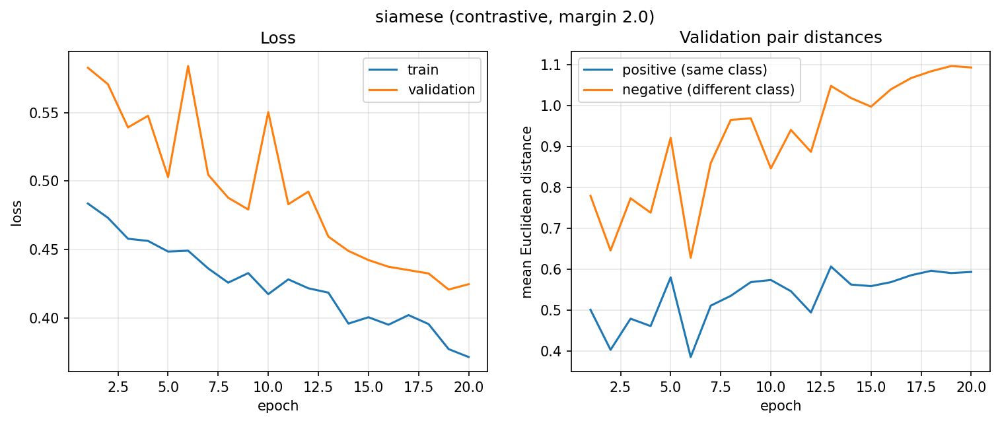

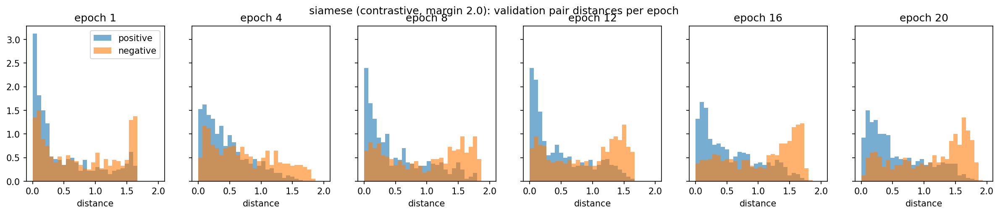

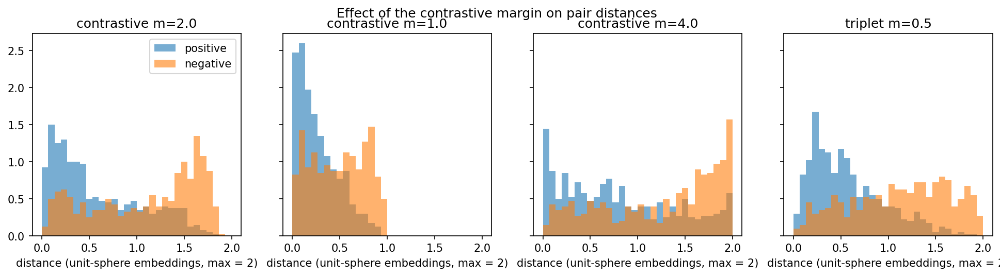

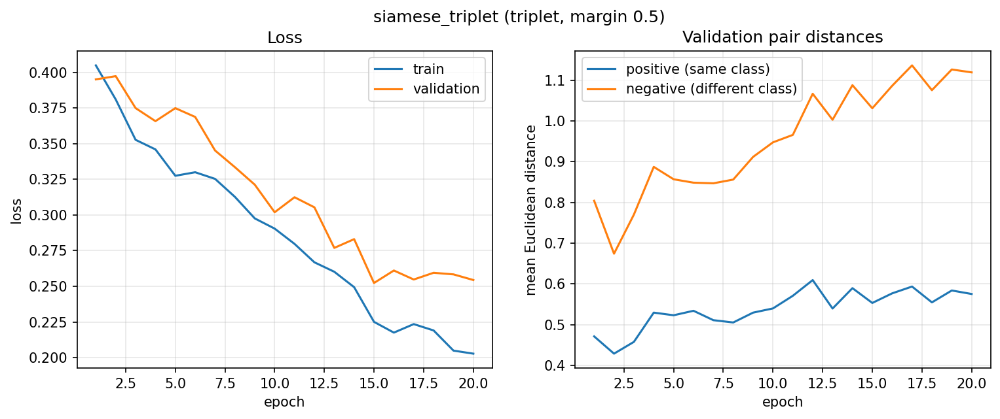

synced to /content/drive/MyDrive/videosense


In [12]:
!python evaluate.py --tasks margins
for f in ['siamese_curves', 'siamese_distance_hist', 'siamese_margin_hist',
          'siamese_triplet_curves']:
    display(Image(f'figures/{f}.png', width=1000))
sync()

## Part 4: Two-stream fusion

* Ex. 21: concat late fusion → `models/twostream_ucf101.pt`
* Ex. 22: ablation with RGB-only, flow-only, concat, average and attention
* Ex. 23: attention fusion, reports the learned α
* Section 8.4: cross-attention fusion (flow queries RGB and vice versa)

fusion=rgb | 10 classes | train 870 | val 342
Epoch 1/30 | Loss: 2.4034 | Train Acc: 0.178 | Val Top-1: 0.240 | Val Top-5: 0.731
Epoch 2/30 | Loss: 2.0920 | Train Acc: 0.273 | Val Top-1: 0.213 | Val Top-5: 0.658
Epoch 3/30 | Loss: 1.9598 | Train Acc: 0.318 | Val Top-1: 0.260 | Val Top-5: 0.731
Epoch 4/30 | Loss: 1.9204 | Train Acc: 0.369 | Val Top-1: 0.211 | Val Top-5: 0.649
Epoch 5/30 | Loss: 1.9005 | Train Acc: 0.387 | Val Top-1: 0.336 | Val Top-5: 0.807
Epoch 6/30 | Loss: 1.7942 | Train Acc: 0.426 | Val Top-1: 0.377 | Val Top-5: 0.825
Epoch 7/30 | Loss: 1.6993 | Train Acc: 0.464 | Val Top-1: 0.439 | Val Top-5: 0.889
Epoch 8/30 | Loss: 1.5948 | Train Acc: 0.550 | Val Top-1: 0.430 | Val Top-5: 0.877
Epoch 9/30 | Loss: 1.6615 | Train Acc: 0.492 | Val Top-1: 0.383 | Val Top-5: 0.816
Epoch 10/30 | Loss: 1.5685 | Train Acc: 0.539 | Val Top-1: 0.380 | Val Top-5: 0.751
Epoch 11/30 | Loss: 1.4757 | Train Acc: 0.589 | Val Top-1: 0.442 | Val Top-5: 0.830
Epoch 12/30 | Loss: 1.4861 | Train Acc:

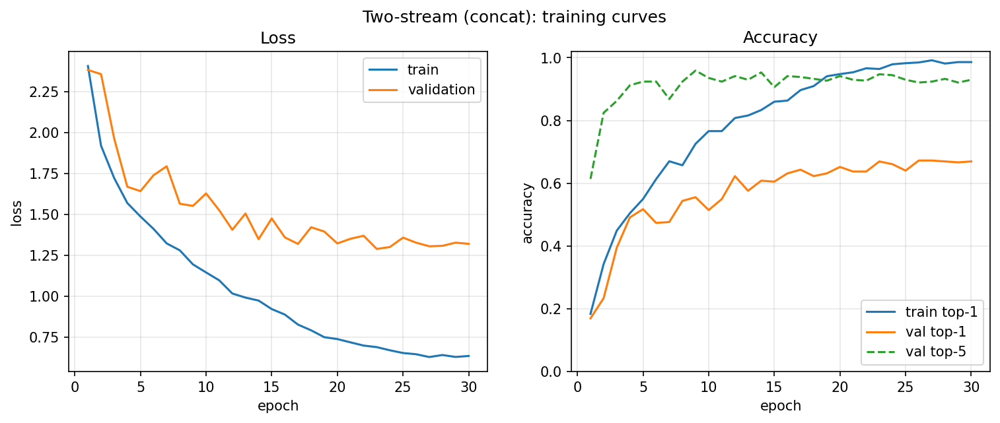

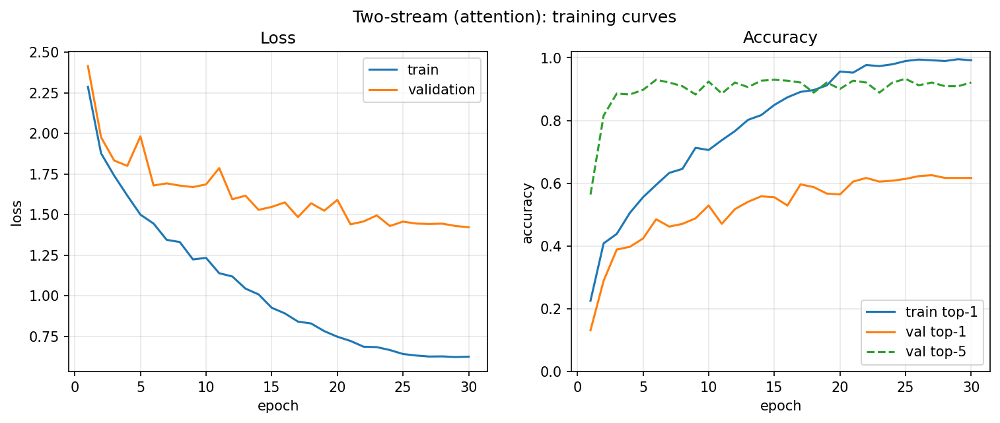

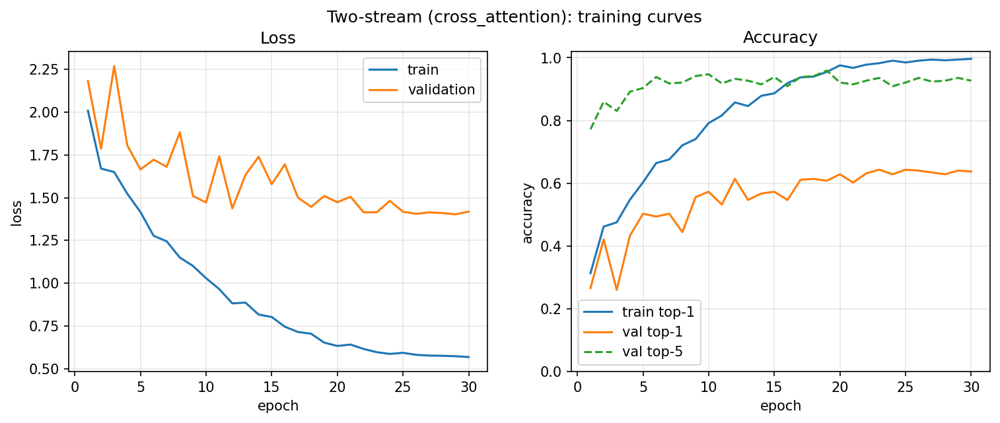

synced to /content/drive/MyDrive/videosense


In [13]:
for mode in ['rgb', 'flow', 'concat', 'average', 'attention', 'cross_attention']:
    !python train_fusion.py --fusion {mode} --epochs 30
for mode in ['concat', 'attention', 'cross_attention']:
    display(Image(f'figures/fusion_{mode}_curves.png', width=1000))
sync()

## Part 5: Evaluation, visualisation, interpretation

The `--cm_model` flag picks the model whose top-3 confused pairs are analysed.
The default is C3D, because a near-perfect model has too few errors to analyse.

In [14]:
!python evaluate.py --tasks report confusion tsne gradcam tta complexity per_class margins tables --cm_model c3d
!python make_diagrams.py
sync()


##### report #####
                                                
=== C3D (scratch) ===
Top-1 Accuracy: 0.5175 | Top-5 Accuracy: 0.8772 | macro-F1: 0.5107
                  precision    recall  f1-score   support

         Archery      0.382     0.317     0.347        41
    BabyCrawling      0.447     0.600     0.512        35
      Basketball      0.568     0.714     0.633        35
         Fencing      0.667     0.647     0.657        34
HandstandWalking      0.379     0.324     0.349        34
         PullUps      0.441     0.536     0.484        28
         PushUps      0.259     0.233     0.246        30
         Surfing      0.912     0.939     0.925        33
  WalkingWithDog      0.541     0.556     0.548        36
            YoYo      0.522     0.333     0.407        36

        accuracy                          0.518       342
       macro avg      0.512     0.520     0.511       342
    weighted avg      0.512     0.518     0.510       342

                           

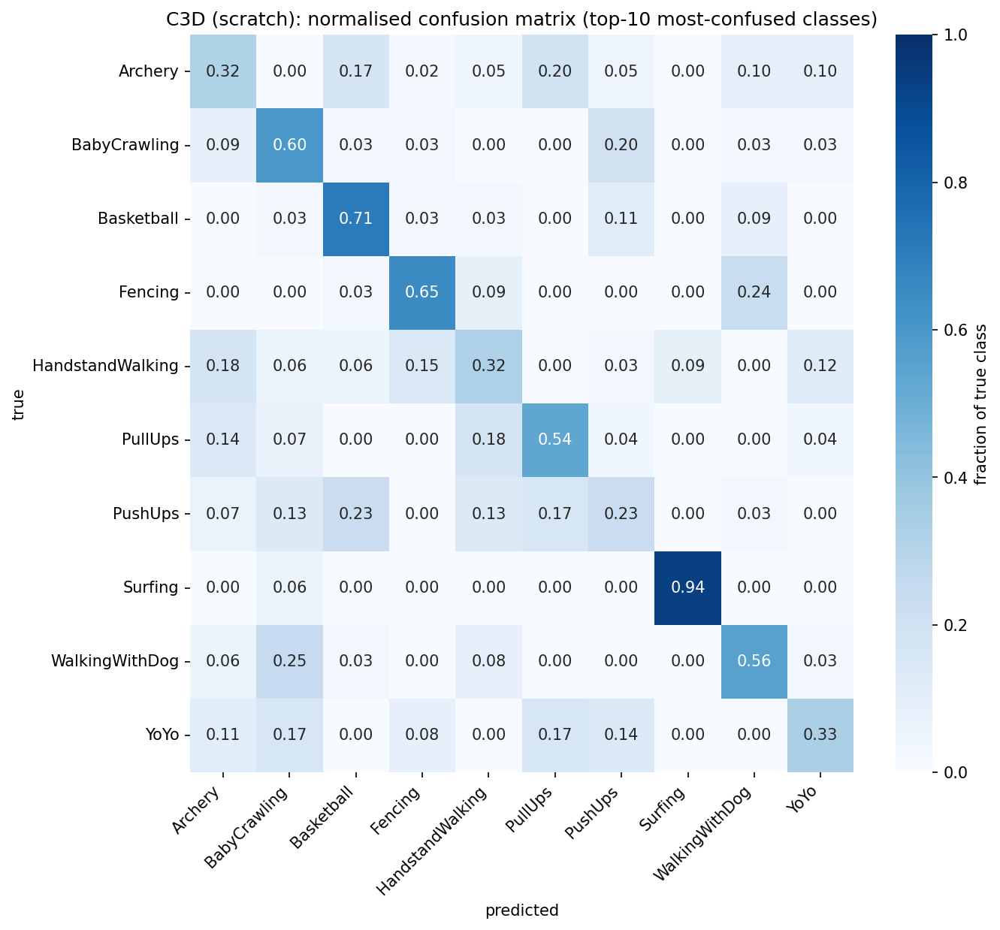

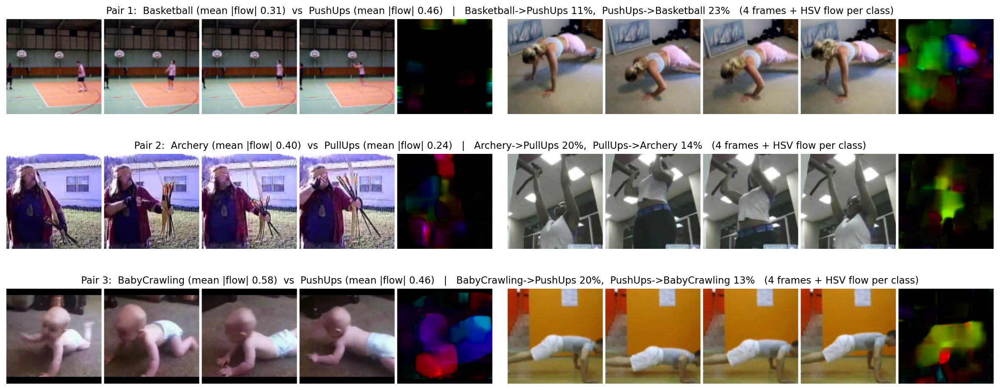

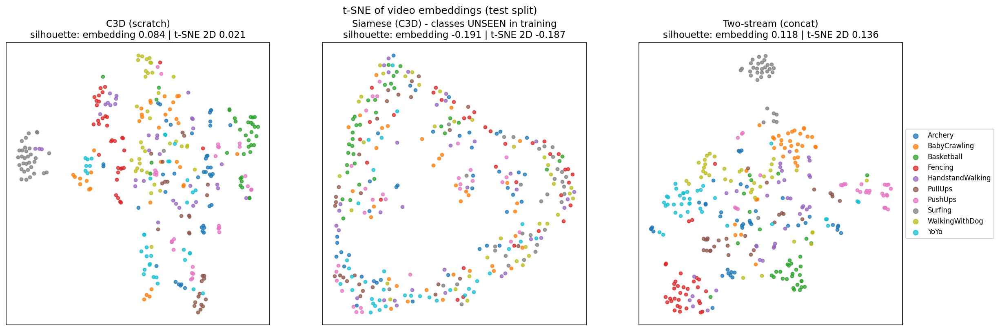

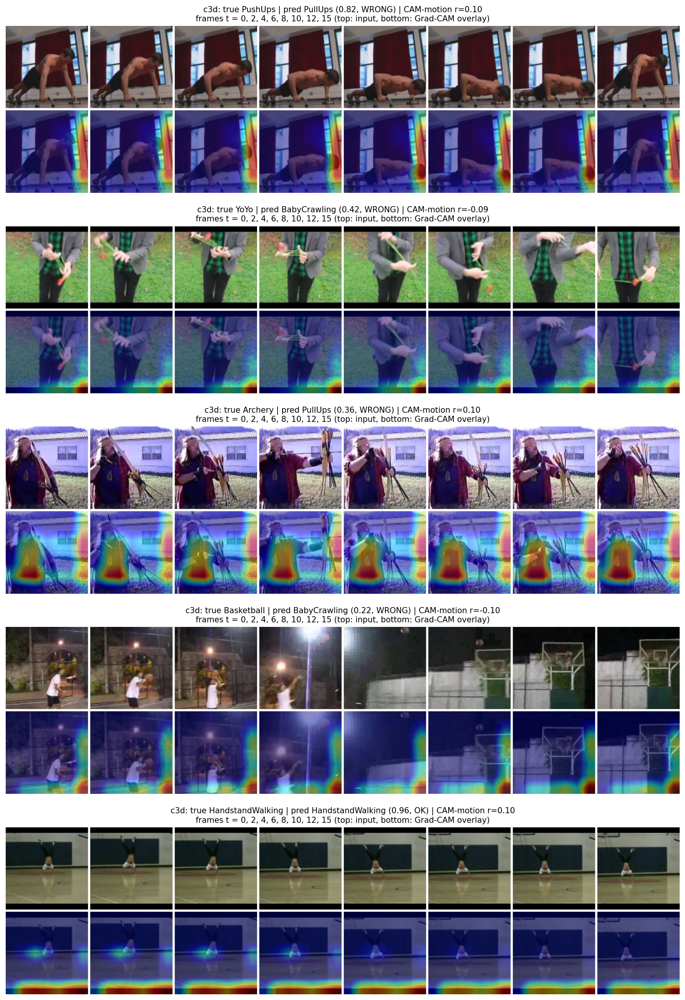

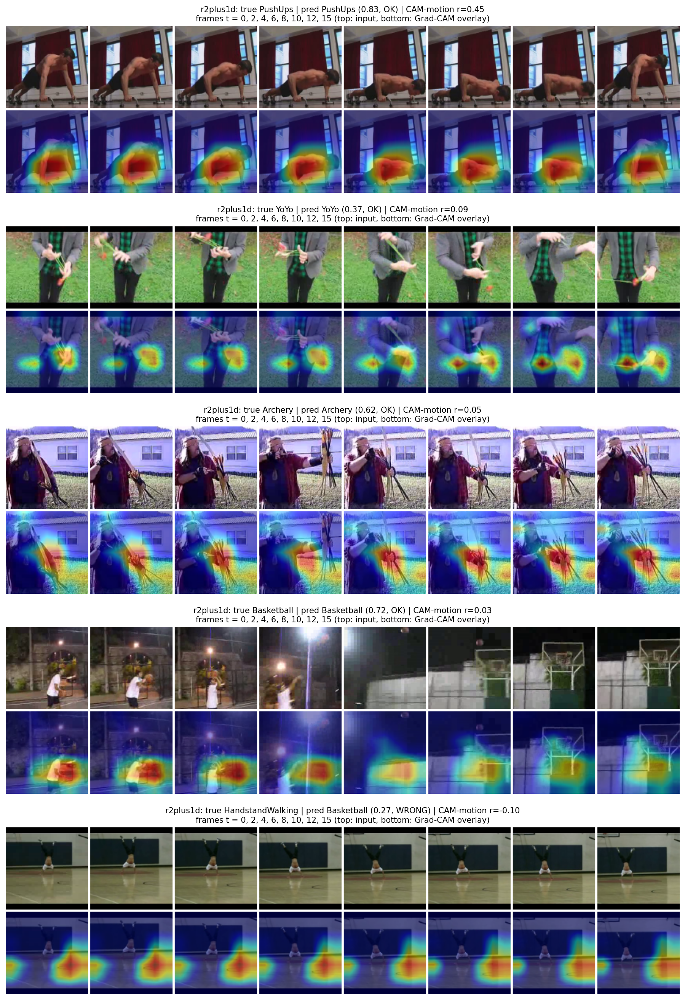

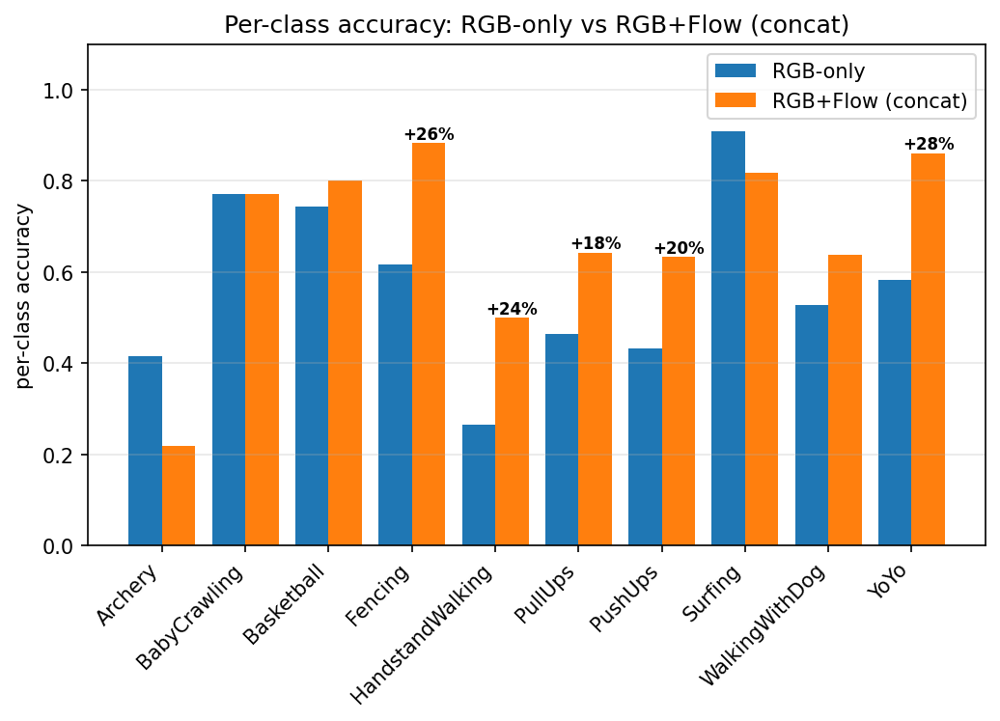

# VideoSense results tables

## Classification (mini UCF101, testlist01)

| Model | Top-1 | Top-5 | Best-epoch top-1 | Train top-1 | Params | GFLOPs |
|---|---|---|---|---|---|---|
| c3d | 51.8% | 87.7% | 52.3% | 89.7% | 63,362,186 | 77.1 |
| r2plus1d | 94.2% | 100.0% | 94.2% | 99.9% | 31,305,255 | 81.0 |
| fusion_attention | 61.7% | 92.1% | 62.6% | 99.2% | 60,045,899 | 153.4 |
| fusion_average | 66.7% | 94.4% | 67.0% | 99.4% | 60,051,028 | 153.4 |
| fusion_concat | 67.0% | 93.0% | 67.3% | 98.6% | 60,051,018 | 153.4 |
| fusion_cross_attention | 63.7% | 92.7% | 64.3% | 99.7% | 63,203,914 | 153.4 |
| fusion_flow | 51.5% | 90.9% | 55.6% | 94.8% | 30,024,650 | 76.4 |
| fusion_rgb | 57.3% | 90.4% | 59.1% | 91.8% | 30,026,378 | 77.0 |

## Label smoothing (C3D)

| label_smoothing | run | Top-1 | Top-5 | Train top-1 | train-val gap |
|---|---|---|---|---|---|
| 0.0 | c3d_ls0.0 | 51.5% | 90.6% | 86.2% | 34.8% |
| 0.1 | c3d | 51.8% | 87.7% | 89.7% | 37.9% |
| 0.2 | c3d_ls0.2 | 61.4% | 90.9% | 92

In [15]:
for f in ['confusion_matrix_c3d', 'confused_pairs_c3d', 'tsne_comparison',
          'gradcam_c3d', 'gradcam_r2plus1d', 'per_class_fusion_vs_rgb']:
    if os.path.exists(f'figures/{f}.png'):
        display(Image(f'figures/{f}.png', width=1100))
print(open('results/results_tables.md').read())

## Deliverables: requirements.txt + ZIP

Section 11.1 asks for `pip freeze > requirements.txt`. Change `ZIP_NAME`
to your own name before running the cell.

In [16]:
!pip freeze > requirements.txt
ZIP_NAME = 'Virupakshappa_Kruthika_VideoSense'
!rm -f /content/{ZIP_NAME}.zip
!cd /content && zip -qr {ZIP_NAME}.zip videosense -x 'videosense/data/*' 'videosense/models/*.pt' 'videosense/**/__pycache__/*'
!cd /content && zip -q {ZIP_NAME}.zip videosense/models/c3d_ucf101.pt videosense/models/siamese_ucf101.pt videosense/models/twostream_ucf101.pt videosense/models/r2plus1d.pt
!cp /content/{ZIP_NAME}.zip "{DRIVE_PROJECT}/../"
!ls -lh /content/{ZIP_NAME}.zip

-rw-r--r-- 1 root root 685M Oct 24 06:20 /content/Virupakshappa_Kruthika_VideoSense.zip
